## Mira primero: una plantilla, tres planos

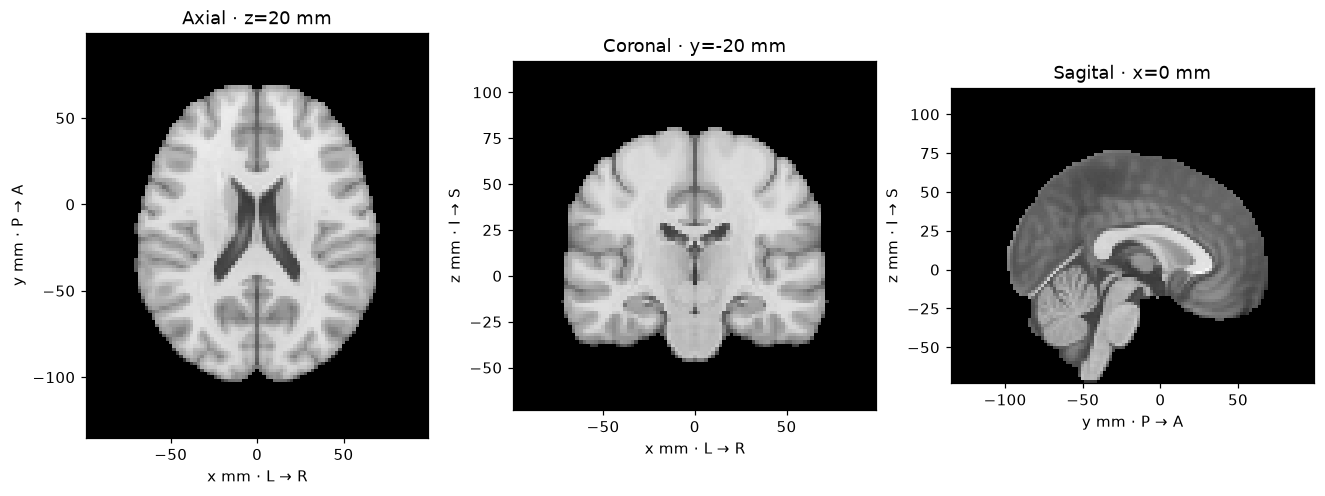

Cortes axial, coronal y sagital de una plantilla pública de referencia. Los ejes indican dirección y milímetros.

# Imágenes médicas con Python

**Juan Calderón · UNAH · ML Honduras 2026**

Ejecuta de arriba abajo con el triángulo de cada celda o **Mayús + Enter**. Las imágenes iniciales ya están guardadas; los deslizadores aparecen al ejecutar las celdas de los gráficos.

### Cómo cambiar una imagen

Mueve el deslizador situado encima del resultado y suelta el ratón: Python vuelve a calcular ese gráfico. También puedes escribir el número en el control. `value=...` en el código fija su valor inicial.

Cada gráfico tiene sus propios controles. Moverlos actualiza sus cálculos y su imagen, sin cambiar los ejemplos de otros bloques. En GitHub/PDF sólo verás la salida guardada; para mover los controles, ejecuta en Colab o Jupyter con una sesión activa.

## Bloque 1 · Primero, tres planos

Una imagen es una matriz de valores. Un volumen añade una tercera dirección; cada muestra tridimensional es un vóxel. Usamos una plantilla pública MNI152, no un estudio privado de una persona.

### 1A · Preparar las bibliotecas

`import` carga herramientas. `sys.executable` identifica este Python; `subprocess.run(...)` ejecuta su instalador. `Path(...)` representa la ruta del archivo y `.exists()` comprueba si está disponible. `requisitos` relaciona cada módulo con su paquete. `find_spec(...)` detecta bibliotecas ausentes; `if faltantes` instala sólo las que faltan. `returncode != 0` detecta un fallo y `raise RuntimeError(...)` lo muestra. `print(...)` confirma que terminó.

Esta celda necesita internet sólo si faltan bibliotecas.

In [1]:
import sys, subprocess, importlib.util
from pathlib import Path
from importlib.metadata import version
ruta = Path("datos/mni152_2mm.nii.gz")
requisitos = {"numpy": "numpy>=1.22.4,<3", "matplotlib": "matplotlib>=3.8,<4", "nibabel": "nibabel>=5.2,<6", "scipy": "scipy>=1.8,<2", "ipywidgets": "ipywidgets>=8.1,<9"}
if not ruta.exists():
    requisitos["nilearn"] = "nilearn==0.12.1"
faltantes = [paquete for modulo, paquete in requisitos.items() if importlib.util.find_spec(modulo) is None]
if faltantes:
    instalacion = subprocess.run([sys.executable, "-m", "pip", "install", "-q", *faltantes], capture_output=True, text=True)
    if instalacion.returncode != 0:
        raise RuntimeError("No terminó la preparación. Revisa la conexión y consulta al facilitador. " + instalacion.stderr[-1200:])
print("Bibliotecas disponibles.")

Bibliotecas disponibles.


### 1B · Importar las herramientas

- `numpy as np` permite calcular con matrices; `matplotlib.pyplot as plt` permite dibujar.
- `nibabel as nib` abre archivos NIfTI; `ndimage` reúne filtros de SciPy.
- `ipywidgets as widgets` crea deslizadores que llaman a Python al moverlos.
- `display(...)` muestra esos controles dentro del notebook. `as` asigna un nombre corto; no cambia la biblioteca.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import nibabel as nib
from scipy import ndimage
import ipywidgets as widgets
from IPython.display import display
print("NumPy: matrices · Matplotlib: figuras · NiBabel: NIfTI · SciPy: filtros · ipywidgets: controles")

NumPy: matrices · Matplotlib: figuras · NiBabel: NIfTI · SciPy: filtros · ipywidgets: controles


### 1C · Abrir la plantilla

`if ruta.exists()` elige la copia local cuando está disponible. `nib.load(ruta)` abre el NIfTI y conserva sus metadatos. `else` usa `load_mni152_template(resolution=2)`: Nilearn obtiene la plantilla pública con separación de 2 mm. `fuente` guarda cuál de las dos rutas se usó; `version(...)` consulta la versión instalada y `print(fuente)` la muestra.

In [3]:
if ruta.exists():
    imagen = nib.load(ruta)
    fuente = "Copia pública local: datos/mni152_2mm.nii.gz"
else:
    from nilearn.datasets import load_mni152_template
    imagen = load_mni152_template(resolution=2)
    fuente = "Plantilla distribuida por Nilearn " + version("nilearn")
print(fuente)

Copia pública local: datos/mni152_2mm.nii.gz


### 1D · Comprobar los datos y la geometría

- `as_closest_canonical(...)` ordena los ejes hacia derecha, anterior y superior (RAS+).
- `get_fdata(dtype=np.float32)` obtiene los valores como números decimales de 32 bits.
- `get_zooms()[:3]` obtiene la separación entre centros; `affine` relaciona índices con milímetros.
- `shape` da el tamaño de la matriz. `assert` detiene la ejecución si esta entrada no coincide con la plantilla prevista.
- `allclose(...)` compara números permitiendo pequeños errores decimales. `isfinite(...).all()` rechaza infinitos y valores ausentes; `min()` y `max()` comprueban el rango.

In [4]:
imagen = nib.as_closest_canonical(imagen)
datos = imagen.get_fdata(dtype=np.float32)
pasos = np.array(imagen.header.get_zooms()[:3])
afin = imagen.affine
assert datos.shape == (99, 117, 95) and np.allclose(pasos, [2, 2, 2]), "La entrada no coincide con la plantilla docente de 2 mm."
assert nib.aff2axcodes(afin) == ("R", "A", "S") and np.allclose(afin[:3, :3], np.diag(pasos)), "Revisa la orientación de la entrada."
assert np.isfinite(datos).all() and datos.min() >= 0 and datos.max() <= 1, "Revisa el rango de la plantilla."
print("Volumen:", datos.shape, "· separación entre centros:", pasos, "mm · orientación RAS+")

Volumen: (99, 117, 95) · separación entre centros: [2. 2. 2.] mm · orientación RAS+


### 1E · Relacionar índices y milímetros

`np.arange(n)` produce los índices 0, 1, …, n−1. Para convertirlos a milímetros, multiplicamos por el espaciado y sumamos el origen de `afin`. `x`, `y` y `z` contienen las coordenadas de los centros.

`extension` fija los bordes exteriores del dibujo: resta o suma 1 mm, la mitad de un vóxel. `[0]` toma el primer centro y `[-1]`, el último. `z_min` y `z_max` serán los límites de los deslizadores.

In [5]:
x = afin[0, 3] + pasos[0] * np.arange(datos.shape[0])
y = afin[1, 3] + pasos[1] * np.arange(datos.shape[1])
z = afin[2, 3] + pasos[2] * np.arange(datos.shape[2])
extension = [x[0]-1, x[-1]+1, y[0]-1, y[-1]+1]
z_min, z_max = int(z[0]), int(z[-1])
print(f"Planos axiales: {z_min} a {z_max} mm, separados {pasos[2]:g} mm.")

Planos axiales: -72 a 116 mm, separados 2 mm.


### 1F · Preparar los tres planos

`datos[:, :, 46]` mantiene todas las posiciones x/y y fija un índice z: obtiene un corte axial. `datos[:, 57, :]` fija y; `datos[49, :, :]` fija x. `:` significa «todas las posiciones». `.T` intercambia filas y columnas para dibujar los ejes correctamente.

Las listas `extensiones`, `titulos` y `ejes` guardan los límites, nombres y etiquetas de cada vista. `f"...{valor}..."` inserta un valor dentro del texto.

In [6]:
cortes = [datos[:, :, 46].T, datos[:, 57, :].T, datos[49, :, :].T]
extensiones = [extension, [x[0]-1, x[-1]+1, z[0]-1, z[-1]+1], [y[0]-1, y[-1]+1, z[0]-1, z[-1]+1]]
titulos = [f"Axial · z={z[46]:.0f} mm", f"Coronal · y={y[57]:.0f} mm", f"Sagital · x={x[49]:.0f} mm"]
ejes = [("x mm · L → R", "y mm · P → A"), ("x mm · L → R", "z mm · I → S"), ("y mm · P → A", "z mm · I → S")]
print("Planos preparados:", " | ".join(titulos))

Planos preparados: Axial · z=20 mm | Coronal · y=-20 mm | Sagital · x=0 mm


### 1G · Mostrar las imágenes

`plt.subplots(1, 3)` crea una figura con tres paneles; `figsize` fija su tamaño. `zip(...)` reúne la imagen, los límites y las etiquetas correspondientes a cada panel. `for` repite el dibujo tres veces.

`imshow(...)` convierte una matriz en imagen: `cmap="gray"` usa grises; `origin="lower"` sitúa la primera fila abajo; `extent` asigna milímetros; `vmin=0, vmax=1` fija la misma escala. `set(...)` escribe título y ejes; `plt.show()` muestra la figura. Los mensajes finales registran fuente y versiones.

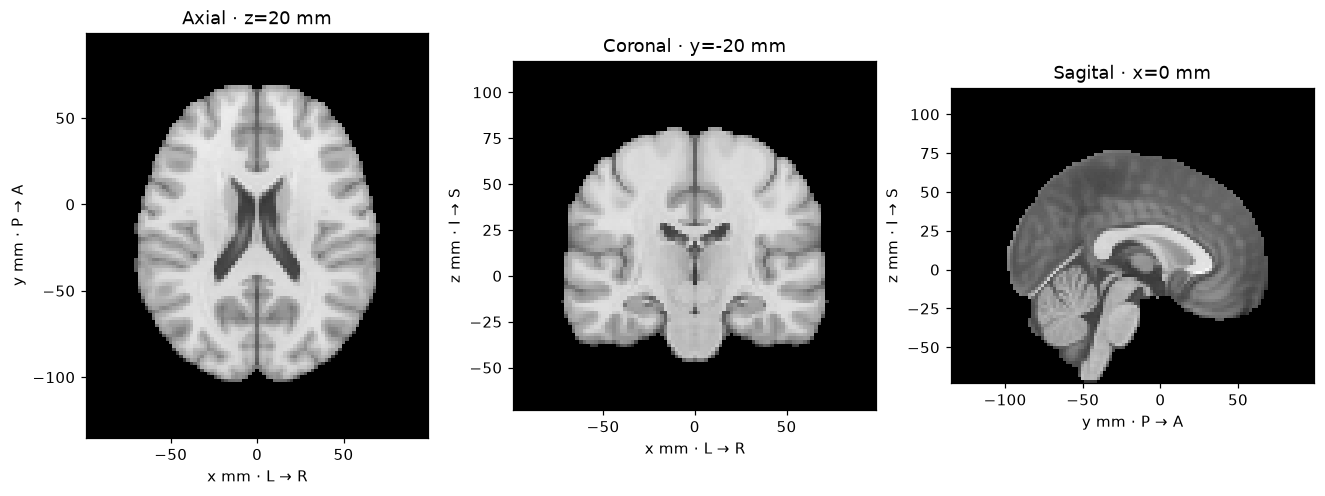

Copia pública local: datos/mni152_2mm.nii.gz
Volumen: (99, 117, 95) · espaciado: [2. 2. 2.] mm · Python 3.12.14
Versiones: numpy 2.5.4, matplotlib 3.11.2, nibabel 5.4.2, scipy 1.18.1, ipywidgets 8.1.9


In [7]:
fig, ax = plt.subplots(1, 3, figsize=(12, 4.4), layout="constrained")
for panel, matriz, limites, titulo, etiquetas in zip(ax, cortes, extensiones, titulos, ejes):
    panel.imshow(matriz, cmap="gray", origin="lower", extent=limites, vmin=0, vmax=1)
    panel.set(title=titulo, xlabel=etiquetas[0], ylabel=etiquetas[1])
plt.show()
print(f"{fuente}\nVolumen: {datos.shape} · espaciado: {pasos} mm · Python {sys.version.split()[0]}")
print("Versiones: " + ", ".join(f"{nombre} {version(nombre)}" for nombre in requisitos))

## Bloque 2 · Posición y contraste

La posición elige un plano; el contraste decide cómo se pintan sus valores. Cambiar el contraste no modifica los números de la matriz.

### 2A · Elegir y extraer un corte

**Cambia `z_mm` si deseas una posición distinta.** `np.abs(z - z_mm)` calcula la distancia de cada plano a la posición solicitada. `.argmin()` encuentra el más cercano e `int(...)` convierte su índice a entero. `datos[:, :, k].T` extrae ese plano y `.copy()` conserva una copia.

La rejilla avanza de 2 en 2 mm: al pedir **25 mm**, se muestra **24 mm** (el menor índice en un empate). No se inventa un corte de 25 mm; el mensaje distingue lo solicitado de lo mostrado.

In [8]:
z_mm = 20  # Posición que deseas consultar, en milímetros.
k = int(np.abs(z - z_mm).argmin())
corte = datos[:, :, k].T.copy()
print(f"Solicitado: {z_mm:g} mm · plano mostrado: {z[k]:g} mm · índice k={k}")

Solicitado: 20 mm · plano mostrado: 20 mm · índice k=46


### 2B · Elegir la ventana de grises

`ventana = (0.35, 0.90)` es una pareja: el primer valor se dibuja negro y el segundo, blanco. Los valores intermedios se reparten en grises. `[0]` y `[1]` seleccionan esos extremos. `assert` comprueba que estén ordenados. La ventana cambia el dibujo, no los valores del corte.

In [9]:
ventana = (0.35, 0.90)
assert ventana[0] < ventana[1], "El primer extremo debe ser menor que el segundo."
print("Negro desde", ventana[0], "· blanco desde", ventana[1])

Negro desde 0.35 · blanco desde 0.9


### 2C · Comparar y comprobar

**Ejecuta y mueve `z_mm` o los dos extremos de `ventana` debajo del código.** El gráfico se actualiza al soltar el control. Prueba 20 → 25 mm y observa la posición realmente mostrada en el título.

- `def ver_contraste(...)` define una función: el código sangrado se repite con cada cambio. Sus variables son locales a este gráfico.
- `if ...` y `return` evitan una ventana de ancho cero. `zip` aplica una ventana distinta a cada panel; `vmin/vmax` son sus extremos.
- `suptitle(...)` pone un título común. `array_equal(...)` comprueba que la matriz original no cambió.
- `widgets.interactive(...)` conecta los argumentos con controles. `IntSlider` usa enteros y `FloatRangeSlider` elige dos límites numéricos. `value` fija el valor inicial; `min/max/step`, el recorrido. `continuous_update=False` espera a soltar el deslizador; `display` lo muestra.

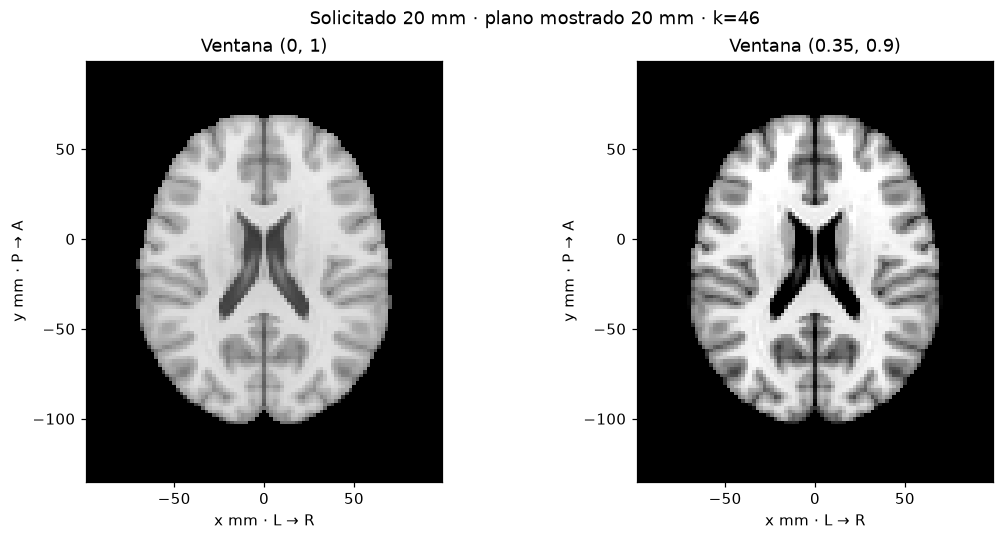

Los valores originales se conservan: True


In [10]:
def ver_contraste(z_mm, ventana):
    k = int(np.abs(z - z_mm).argmin())
    corte = datos[:, :, k].T
    if ventana[0] >= ventana[1]:
        print("Separa los dos extremos de la ventana: negro debe ser menor que blanco.")
        return
    fig, ax = plt.subplots(1, 2, figsize=(10, 4.8), layout="constrained")
    for panel, limites in zip(ax, [(0, 1), ventana]):
        panel.imshow(corte, cmap="gray", origin="lower", extent=extension,
                     vmin=limites[0], vmax=limites[1])
        panel.set(title=f"Ventana {limites}", xlabel="x mm · L → R", ylabel="y mm · P → A")
    fig.suptitle(f"Solicitado {z_mm:g} mm · plano mostrado {z[k]:g} mm · k={k}")
    plt.show()
    print("Los valores originales se conservan:", np.array_equal(corte, datos[:, :, k].T))

control_contraste = widgets.interactive(
    ver_contraste,
    z_mm=widgets.IntSlider(value=20, min=z_min, max=z_max, continuous_update=False),
    ventana=widgets.FloatRangeSlider(value=(0.35, 0.90), min=0, max=1, step=0.01, continuous_update=False),
)
display(control_contraste)

## Bloque 3 · Histograma

El eje horizontal contiene intensidades y el vertical cuenta píxeles. Excluir el fondo evita que sus muchos ceros dominen la gráfica.

### 3A · Elegir qué valores contar

`bins = 20` fija 20 intervalos para contar intensidades. `corte > 1e-6` produce una matriz de verdaderos/falsos: selecciona valores mayores que 0.000001 y excluye el fondo casi nulo. `corte[soporte]` reúne sólo esos valores. `.size` cuenta elementos; la resta indica cuántos se excluyeron.

Un histograma cuenta valores; no conserva dónde estaba cada píxel.

In [11]:
bins = 20
soporte = corte > 1e-6
valores = corte[soporte]
print(f"Total: {corte.size} · soporte: {valores.size} · excluidos: {corte.size-valores.size}")

Total: 11583 · soporte: 4859 · excluidos: 6724


### 3B · Dibujar los histogramas

**Mueve `bins` de 20 a 80:** las barras se estrechan, pero la cantidad de píxeles se conserva. `z_mm` elige qué corte se cuenta.

`ver_histograma(...)` extrae el corte y vuelve a calcular el soporte cada vez. `.ravel()` reúne todos los píxeles en una lista; la selección `corte[corte > 1e-6]` excluye el fondo. `hist(..., bins=bins, range=(0, 1))` cuenta valores dentro de intervalos entre 0 y 1. `color` y `edgecolor` colorean barras y bordes. `set(...)` rotula los ejes; `suptitle(...)` informa la posición. Los dos `IntSlider` controlan posición y número de intervalos.

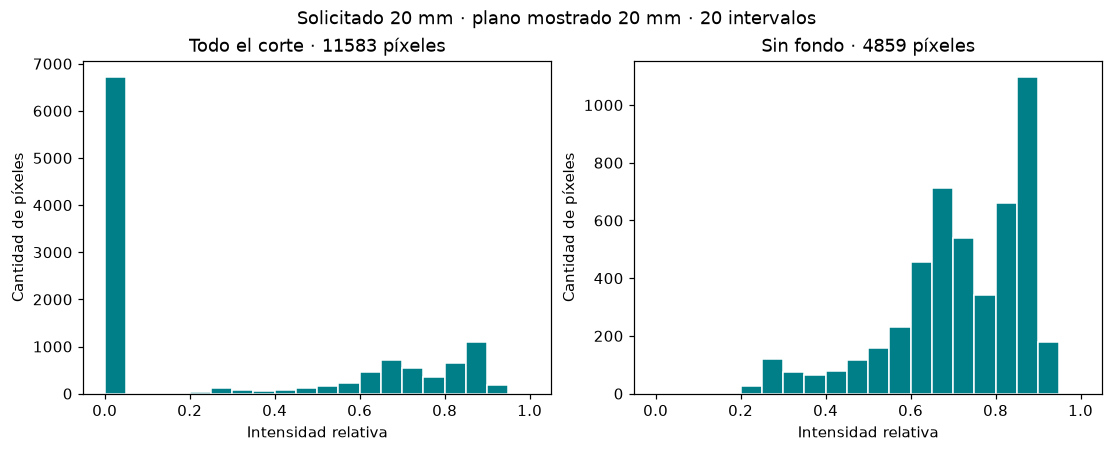

Total: 11583 · sin fondo: 4859 · excluidos: 6724


In [12]:
def ver_histograma(z_mm, bins):
    k = int(np.abs(z - z_mm).argmin())
    corte = datos[:, :, k].T
    valores = corte[corte > 1e-6]
    fig, ax = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
    for panel, muestra, nombre in zip(ax, [corte.ravel(), valores], ["Todo el corte", "Sin fondo"]):
        panel.hist(muestra, bins=bins, range=(0, 1), color="#007f89", edgecolor="white")
        panel.set(title=f"{nombre} · {muestra.size} píxeles",
                  xlabel="Intensidad relativa", ylabel="Cantidad de píxeles")
    fig.suptitle(f"Solicitado {z_mm:g} mm · plano mostrado {z[k]:g} mm · {bins} intervalos")
    plt.show()
    print(f"Total: {corte.size} · sin fondo: {valores.size} · excluidos: {corte.size-valores.size}")

control_histograma = widgets.interactive(
    ver_histograma,
    z_mm=widgets.IntSlider(value=20, min=z_min, max=z_max, continuous_update=False),
    bins=widgets.IntSlider(value=20, min=5, max=100, step=5, continuous_update=False),
)
display(control_histograma)

## Bloque 4 · Percentil y máscara

Un percentil elige un umbral según los valores del corte. Una máscara marca qué posiciones cumplen una comparación.

### 4A · Calcular el umbral

`np.percentile(valores, percentil)` ordena conceptualmente las intensidades y encuentra el valor por debajo del cual queda el porcentaje indicado. `percentil = 90` solicita p90; **no significa intensidad 0.90**. `assert` restringe el porcentaje a 0–100. En `:.6f`, el 6 solicita seis decimales al imprimir.

In [13]:
percentil = 90
assert 0 <= percentil <= 100
umbral = np.percentile(valores, percentil)
print(f"p{percentil} → intensidad umbral {umbral:.6f}")

p90 → intensidad umbral 0.878431


### 4B · Construir la máscara

`corte >= umbral` marca las posiciones que alcanzan el umbral. `&` exige cumplir también el soporte; los paréntesis agrupan la comparación. La máscara guarda `True` o `False` en cada píxel. `.sum()` cuenta los verdaderos como unos. Dividir entre `valores.size` y multiplicar por 100 da el porcentaje del soporte seleccionado; los empates pueden hacerlo mayor que 10 % para p90.

In [14]:
mascara = soporte & (corte >= umbral)
porcentaje = 100 * mascara.sum() / valores.size
print(f"Seleccionados: {mascara.sum()} / {valores.size} = {porcentaje:.2f}% del soporte")

Seleccionados: 523 / 4859 = 10.76% del soporte


### 4C · Ver la regla y su resultado

**Mueve `percentil` de 90 a 75:** observa cómo se desplaza el umbral y cambia la máscara. `z_mm` cambia el corte y recalcula todo el análisis.

`if valores.size == 0` detecta un plano de fondo y `return` evita calcular un percentil vacío. `percentile`, `>=`, `&` y `sum` calculan umbral, máscara y porcentaje. `hist` dibuja los conteos; `axvline` señala el umbral y `legend` muestra su etiqueta. `imshow` dibuja la máscara; `interpolation="nearest"` mantiene sus casillas nítidas. `widgets.interactive` ejecuta esta función con los dos deslizadores; `value=90` es el percentil inicial.

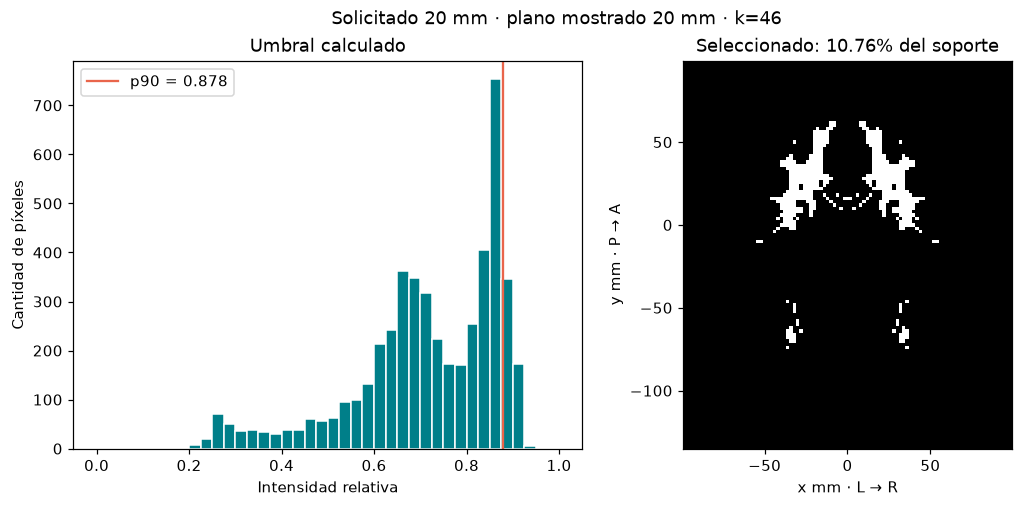

Umbral: 0.878431 · seleccionados: 523 / 4859


In [15]:
def ver_percentil(z_mm, percentil):
    k = int(np.abs(z - z_mm).argmin())
    corte = datos[:, :, k].T
    soporte = corte > 1e-6
    valores = corte[soporte]
    if valores.size == 0:
        print(f"El plano {z[k]:g} mm sólo contiene fondo. Elige otra posición.")
        return
    umbral = np.percentile(valores, percentil)
    mascara = soporte & (corte >= umbral)
    porcentaje = 100 * mascara.sum() / valores.size
    fig, ax = plt.subplots(1, 2, figsize=(10, 4.5), layout="constrained")
    ax[0].hist(valores, bins=40, range=(0, 1), color="#007f89", edgecolor="white")
    ax[0].axvline(umbral, color="#e9654b", label=f"p{percentil} = {umbral:.3f}")
    ax[0].legend()
    ax[0].set(xlabel="Intensidad relativa", ylabel="Cantidad de píxeles", title="Umbral calculado")
    ax[1].imshow(mascara, cmap="gray", origin="lower", extent=extension,
                 vmin=0, vmax=1, interpolation="nearest")
    ax[1].set(title=f"Seleccionado: {porcentaje:.2f}% del soporte", xlabel="x mm · L → R", ylabel="y mm · P → A")
    fig.suptitle(f"Solicitado {z_mm:g} mm · plano mostrado {z[k]:g} mm · k={k}")
    plt.show()
    print(f"Umbral: {umbral:.6f} · seleccionados: {mascara.sum()} / {valores.size}")

control_percentil = widgets.interactive(
    ver_percentil,
    z_mm=widgets.IntSlider(value=20, min=z_min, max=z_max, continuous_update=False),
    percentil=widgets.IntSlider(value=90, min=0, max=100, continuous_update=False),
)
display(control_percentil)

## Bloque 5 · Curva de nivel sobre el cerebro

La curva une lugares de igual intensidad; la máscara selecciona una región. Ninguna de las dos asigna por sí sola una estructura anatómica.

### 5A · Fijar un nivel y una región

`nivel = 0.7` fija una intensidad absoluta. `corte >= nivel` selecciona valores de 0.7 o mayores; `& soporte` excluye el fondo. `region.sum()` cuenta la selección. Una curva representa igualdad con el nivel; una región incluye también valores superiores.

In [16]:
nivel = 0.7
region = soporte & (corte >= nivel)
print(f"Nivel {nivel}: {region.sum()} posiciones de la región seleccionada")

Nivel 0.7: 2820 posiciones de la región seleccionada


### 5B · Comparar curva y máscara

**Mueve `nivel` de 0.70 a 0.60:** compara la línea sobre el cerebro con la región blanca. También puedes cambiar `z_mm`.

`contour(x, y, corte, levels=[nivel])` calcula una línea de igual intensidad usando coordenadas en milímetros. `colors` y `linewidths` fijan su aspecto; `clabel` escribe el nivel sobre ella. El `if` dibuja curvas sólo si el nivel cruza el rango del corte. La máscara se obtiene con `>=` y se dibuja con `imshow`. `zip` aplica un título a cada panel. `FloatSlider(..., step=0.05)` cambia el nivel de cinco centésimas en cinco centésimas.

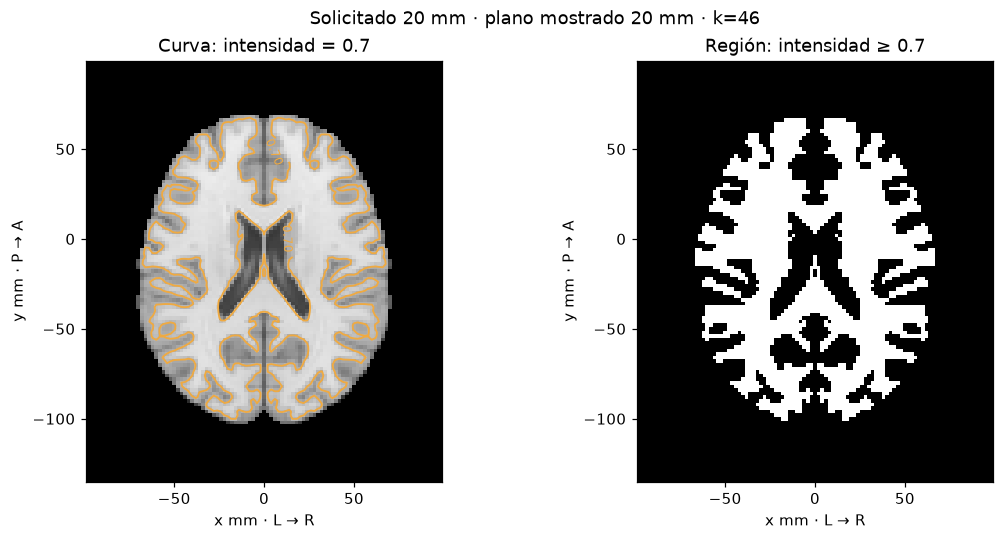

Región seleccionada: 2820 píxeles. Si no hay cruce del nivel, no aparece curva.


In [17]:
def ver_curva(z_mm, nivel):
    k = int(np.abs(z - z_mm).argmin())
    corte = datos[:, :, k].T
    region = (corte > 1e-6) & (corte >= nivel)
    fig, ax = plt.subplots(1, 2, figsize=(10, 4.8), layout="constrained")
    ax[0].imshow(corte, cmap="gray", origin="lower", extent=extension, vmin=0, vmax=1)
    if corte.min() < nivel < corte.max():
        lineas = ax[0].contour(x, y, corte, levels=[nivel], colors=["#efaa42"], linewidths=1.2)
        ax[0].clabel(lineas, fmt="%.2f", fontsize=8)
    ax[1].imshow(region, cmap="gray", origin="lower", extent=extension,
                 vmin=0, vmax=1, interpolation="nearest")
    for panel, titulo in zip(ax, [f"Curva: intensidad = {nivel:g}", f"Región: intensidad ≥ {nivel:g}"]):
        panel.set(title=titulo, xlabel="x mm · L → R", ylabel="y mm · P → A")
    fig.suptitle(f"Solicitado {z_mm:g} mm · plano mostrado {z[k]:g} mm · k={k}")
    plt.show()
    print(f"Región seleccionada: {region.sum()} píxeles. Si no hay cruce del nivel, no aparece curva.")

control_curva = widgets.interactive(
    ver_curva,
    z_mm=widgets.IntSlider(value=20, min=z_min, max=z_max, continuous_update=False),
    nivel=widgets.FloatSlider(value=0.7, min=0.05, max=0.95, step=0.05, continuous_update=False),
)
display(control_curva)

## Bloque 6 · Filtros

La media promedia vecinos, Gauss los pondera por distancia y la mediana escoge el valor central. Compararemos las tres operaciones sobre la misma entrada.

### 6A · Crear una entrada con ruido

`default_rng(semilla)` crea un generador reproducible. `normal(0, sigma_ruido, size=corte.shape)` genera ruido de media cero, desviación `sigma_ruido` y la misma forma que el corte. `astype(np.float32)` fija el tipo numérico. `corte + ruido` crea otra matriz; no modifica el corte original.

`sigma_ruido` controla la amplitud del ruido. `sigma_pixeles` controlará la extensión espacial del filtro gaussiano: son cantidades distintas.

In [18]:
semilla = 2026
sigma_ruido = 0.06
sigma_pixeles = 1.2
rng = np.random.default_rng(semilla)
ruido = rng.normal(0, sigma_ruido, size=corte.shape).astype(np.float32)
ruidosa = corte + ruido
print(f"Ruido añadido: mínimo {ruidosa.min():.3f}, máximo {ruidosa.max():.3f}; corte original conservado.")

Ruido añadido: mínimo -0.239, máximo 1.110; corte original conservado.


### 6B · Calcular la media

`uniform_filter(ruidosa, size=3)` reemplaza cada posición por la media de sus nueve vecinos en una ventana 3 × 3. `mode="reflect"` prolonga los valores reflejándolos en los límites para poder filtrar también los bordes de la imagen. La matriz resultante se guarda en `media`; `.shape` permite comprobar su tamaño.

In [19]:
media = ndimage.uniform_filter(ruidosa, size=3, mode="reflect")
print("Media calculada:", media.shape)

Media calculada: (117, 99)


### 6C · Calcular el filtro gaussiano

`gaussian_filter(..., sigma=sigma_pixeles)` calcula un promedio que da más peso a posiciones cercanas. Un sigma mayor mezcla información de una zona más amplia y puede borrar detalles. `sigma_pixeles * pasos[0]` expresa ese sigma en milímetros: 1.2 píxeles × 2 mm = 2.4 mm. Sigma no es el diámetro total del filtro.

In [20]:
gauss = ndimage.gaussian_filter(ruidosa, sigma=sigma_pixeles, mode="reflect")
print(f"Gauss calculado: sigma={sigma_pixeles} píxeles, {sigma_pixeles*pasos[0]:.1f} mm por eje")

Gauss calculado: sigma=1.2 píxeles, 2.4 mm por eje


### 6D · Calcular la mediana

`median_filter(ruidosa, size=3)` toma nueve valores vecinos, los ordena y elige el quinto. Con ocho valores 10 y un valor 90, devuelve 10; la media devolvería 18.89. `mode="reflect"` trata los límites mediante reflexión. La mediana puede reducir valores aislados extremos, pero también modifica detalles.

In [21]:
mediana = ndimage.median_filter(ruidosa, size=3, mode="reflect")
print("Mediana calculada:", mediana.shape)

Mediana calculada: (117, 99)


### 6E · Comparar las cuatro imágenes

**Mueve `sigma_px` para cambiar Gauss y `ruido_sd` para cambiar el ruido.** `z_mm` selecciona el plano. Los cuatro paneles se recalculan juntos.

La función crea de nuevo el generador con semilla 2026: cambiar sólo sigma conserva exactamente el mismo ruido. Los tres filtros reciben la misma `ruidosa`. `subplots(2, 2)` crea cuatro paneles; `ax.ravel()` permite recorrerlos con un `for`. `zip` empareja panel, matriz y título. `vmin=0, vmax=1` conserva una escala común, aunque el ruido produzca valores fuera de ella. Los dos `FloatSlider` ajustan sigma y desviación del ruido; sus `value` indican los valores iniciales.

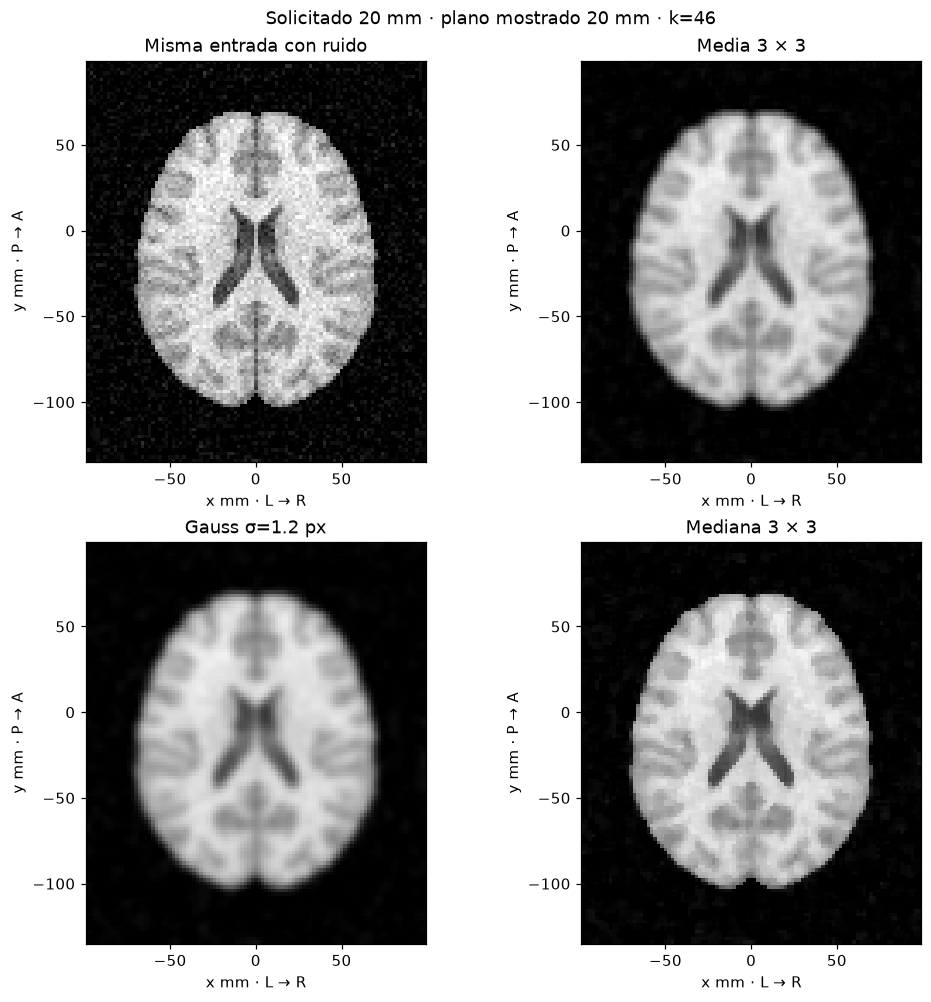

Sigma Gauss: 2.4 mm por eje · ruido SD: 0.06


In [22]:
def ver_filtros(z_mm, sigma_px, ruido_sd):
    k = int(np.abs(z - z_mm).argmin())
    corte = datos[:, :, k].T
    rng = np.random.default_rng(2026)
    ruidosa = corte + rng.normal(0, ruido_sd, size=corte.shape).astype(np.float32)
    media = ndimage.uniform_filter(ruidosa, size=3, mode="reflect")
    gauss = ndimage.gaussian_filter(ruidosa, sigma=sigma_px, mode="reflect")
    mediana = ndimage.median_filter(ruidosa, size=3, mode="reflect")
    matrices = [ruidosa, media, gauss, mediana]
    titulos = ["Misma entrada con ruido", "Media 3 × 3", f"Gauss σ={sigma_px:g} px", "Mediana 3 × 3"]
    fig, ax = plt.subplots(2, 2, figsize=(9, 9), layout="constrained")
    for panel, matriz, titulo in zip(ax.ravel(), matrices, titulos):
        panel.imshow(matriz, cmap="gray", origin="lower", extent=extension, vmin=0, vmax=1)
        panel.set(title=titulo, xlabel="x mm · L → R", ylabel="y mm · P → A")
    fig.suptitle(f"Solicitado {z_mm:g} mm · plano mostrado {z[k]:g} mm · k={k}")
    plt.show()
    print(f"Sigma Gauss: {sigma_px*pasos[0]:g} mm por eje · ruido SD: {ruido_sd:g}")

control_filtros = widgets.interactive(
    ver_filtros,
    z_mm=widgets.IntSlider(value=20, min=z_min, max=z_max, continuous_update=False),
    sigma_px=widgets.FloatSlider(value=1.2, min=0, max=3, step=0.1, continuous_update=False),
    ruido_sd=widgets.FloatSlider(value=0.06, min=0, max=0.2, step=0.01, continuous_update=False),
)
display(control_filtros)

## Bloque 7 · Bordes con Sobel

Un borde es un cambio local, no simplemente una zona brillante. El ruido también genera cambios; suavizar puede reducirlos y borrar detalles.

### 7A · Medir cambios antes de suavizar

`def magnitud_sobel(matriz)` define una operación que acepta una imagen. `sobel(..., axis=1)` mide cambios al recorrer columnas; `axis=0`, al recorrer filas. `**2` eleva al cuadrado y `np.sqrt(dx**2 + dy**2)` combina ambas respuestas en una magnitud sin signo. `return` devuelve esa matriz. La llamada `magnitud_sobel(ruidosa)` aplica la operación a la imagen con ruido.

In [23]:
def magnitud_sobel(matriz):
    dx = ndimage.sobel(matriz, axis=1, mode="reflect")
    dy = ndimage.sobel(matriz, axis=0, mode="reflect")
    return np.sqrt(dx**2 + dy**2)

gradiente = magnitud_sobel(ruidosa)
print("Magnitud antes de suavizar:", gradiente.shape)

Magnitud antes de suavizar: (117, 99)


### 7B · Medir cambios después de Gauss

`magnitud_sobel(gauss)` ejecuta las mismas restas y combinación sobre la imagen suavizada. Sólo cambia la entrada: así podemos atribuir las diferencias al suavizado, manteniendo el operador. `gradiente_suave.shape` comprueba que el resultado mantiene la forma de la imagen.

In [24]:
gradiente_suave = magnitud_sobel(gauss)
print("Magnitud después de Gauss:", gradiente_suave.shape)

Magnitud después de Gauss: (117, 99)


### 7C · Fijar una comparación común

`max(...)` elige un máximo común para colorear ambas magnitudes; `1e-12` evita una escala de ancho cero. `float(...)` convierte los máximos en números simples. `gradiente >= umbral_borde` convierte una respuesta continua en una máscara. `mapas` y `titulos` reúnen magnitudes y máscaras en el mismo orden: antes, después, selección antes y selección después.

In [25]:
maximo_comun = max(float(gradiente.max()), float(gradiente_suave.max()), 1e-12)
umbral_borde = 0.6
mapas = [gradiente, gradiente_suave, gradiente >= umbral_borde, gradiente_suave >= umbral_borde]
titulos = ["Sobel con ruido", f"Sobel tras Gauss σ={sigma_pixeles} px", f"Respuesta ≥ {umbral_borde} antes", f"Respuesta ≥ {umbral_borde} después"]
print(f"Escala común: 0–{maximo_comun:.3f} · umbral de respuesta: {umbral_borde}")

Escala común: 0–3.647 · umbral de respuesta: 0.6


### 7D · Ver magnitudes y selecciones

**Mueve `sigma_px` y `umbral`:** compara cambios locales y posiciones seleccionadas. `ruido_sd` cambia el ruido; `z_mm`, el plano. Cada cambio recalcula ruido, Gauss, Sobel y las dos máscaras.

`magnitud_sobel` aplica el mismo operador antes y después. `max(...)` conserva una escala común. `enumerate(ax.ravel())` devuelve el número `i` y cada panel; `... if i < 2 else ...` usa colores continuos arriba y blanco/negro abajo. `colorbar(...)` añade la escala de respuesta Sobel. Las sumas del mensaje cuentan posiciones seleccionadas. `value=0.6` es el umbral inicial; el control no cambia las figuras de otros bloques.

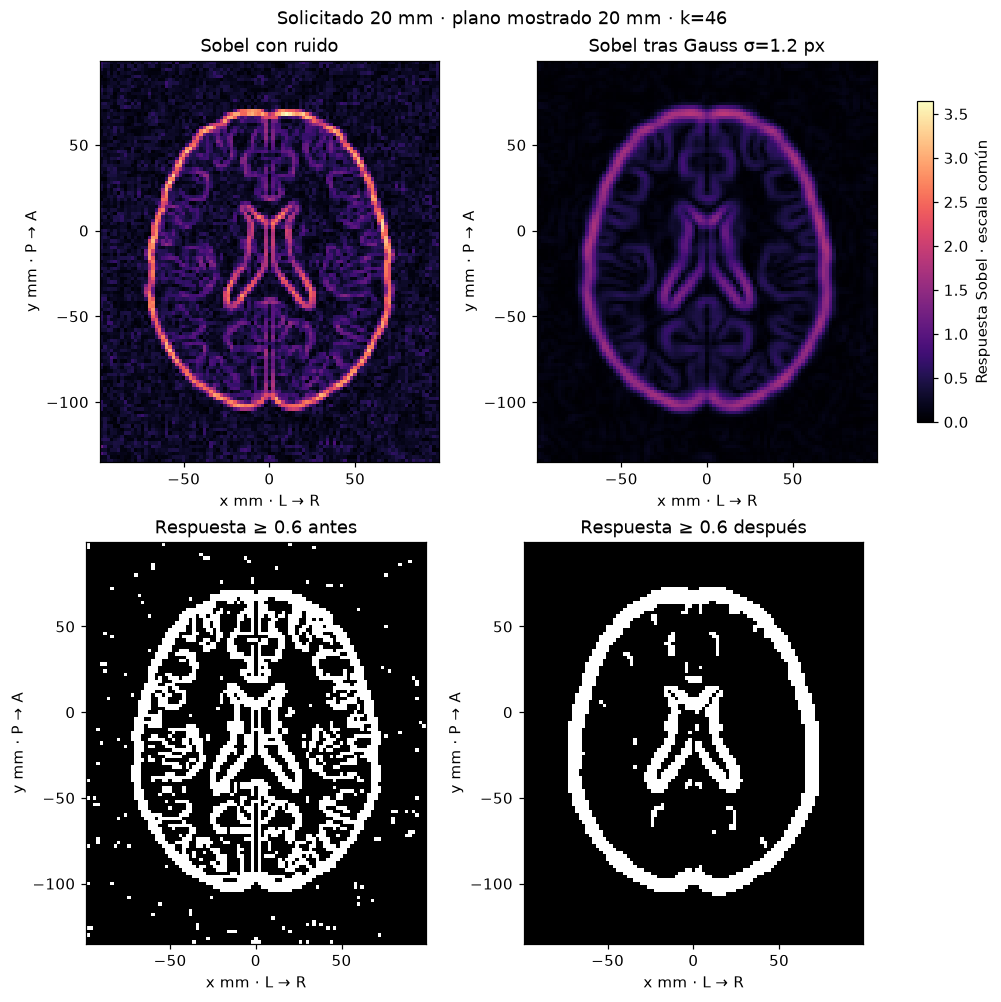

Umbral 0.6: seleccionados antes/después = 2471 / 1495


In [26]:
def ver_bordes(z_mm, sigma_px, ruido_sd, umbral):
    k = int(np.abs(z - z_mm).argmin())
    corte = datos[:, :, k].T
    rng = np.random.default_rng(2026)
    ruidosa = corte + rng.normal(0, ruido_sd, size=corte.shape).astype(np.float32)
    gauss = ndimage.gaussian_filter(ruidosa, sigma=sigma_px, mode="reflect")
    antes, despues = magnitud_sobel(ruidosa), magnitud_sobel(gauss)
    maximo = max(float(antes.max()), float(despues.max()), 1e-12)
    mapas = [antes, despues, antes >= umbral, despues >= umbral]
    titulos = ["Sobel con ruido", f"Sobel tras Gauss σ={sigma_px:g} px",
               f"Respuesta ≥ {umbral:g} antes", f"Respuesta ≥ {umbral:g} después"]
    fig, ax = plt.subplots(2, 2, figsize=(9, 9), layout="constrained")
    for i, panel in enumerate(ax.ravel()):
        panel.imshow(mapas[i], cmap="magma" if i < 2 else "gray", origin="lower",
                     extent=extension, vmin=0, vmax=maximo if i < 2 else 1)
        panel.set(title=titulos[i], xlabel="x mm · L → R", ylabel="y mm · P → A")
    fig.colorbar(ax[0, 0].images[0], ax=ax[0, :], shrink=0.8, label="Respuesta Sobel · escala común")
    fig.suptitle(f"Solicitado {z_mm:g} mm · plano mostrado {z[k]:g} mm · k={k}")
    plt.show()
    print(f"Umbral {umbral:g}: seleccionados antes/después = {(antes >= umbral).sum()} / {(despues >= umbral).sum()}")

control_bordes = widgets.interactive(
    ver_bordes,
    z_mm=widgets.IntSlider(value=20, min=z_min, max=z_max, continuous_update=False),
    sigma_px=widgets.FloatSlider(value=1.2, min=0, max=3, step=0.1, continuous_update=False),
    ruido_sd=widgets.FloatSlider(value=0.06, min=0, max=0.2, step=0.01, continuous_update=False),
    umbral=widgets.FloatSlider(value=0.6, min=0, max=2, step=0.05, continuous_update=False),
)
display(control_bordes)

## Bloque 8 · Conectar las operaciones

El mapa final reúne las operaciones realizadas y sirve para explicar qué cambió en los datos y qué cambió sólo en su representación.

### 8A · Recordar el recorrido

`etapas` es una lista de textos. `\n` produce un salto de línea dentro de cada tarjeta. `replace("\n", " ")` cambia esos saltos por espacios para el mensaje. `" → ".join(...)` reúne los textos con una flecha entre ellos.

In [27]:
etapas = ["Datos públicos\ny geometría", "Mirar cortes\ny contraste", "Contar y\nseleccionar", "Comparar filtros\ny cambios", "Explicar límites\ny evaluar"]
print(" → ".join(etapa.replace("\n", " ") for etapa in etapas))

Datos públicos y geometría → Mirar cortes y contraste → Contar y seleccionar → Comparar filtros y cambios → Explicar límites y evaluar


### 8B · Dibujar el mapa final

`subplots(...)` prepara el lienzo; `set(xlim=..., ylim=...)` fija sus límites y `axis("off")` oculta los ejes. `enumerate(etapas)` asigna una posición a cada texto. `ax.text(...)` escribe las tarjetas: `ha/va` centran el texto y `bbox` dibuja su recuadro. `if indice < ...` evita una flecha después de la última tarjeta. `annotate(...)` dibuja cada flecha desde `xytext` hasta `xy`; `plt.show()` muestra el mapa.

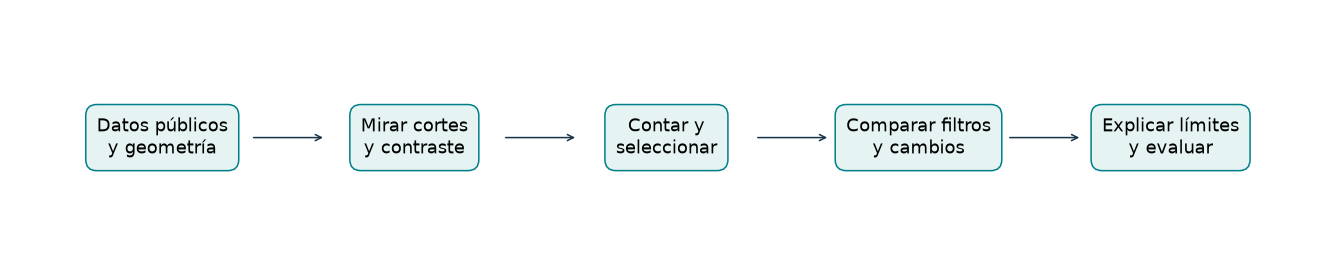

In [28]:
fig, ax = plt.subplots(figsize=(12, 2.4), layout="constrained")
ax.set(xlim=(-0.6, 4.6), ylim=(-0.6, 0.6))
ax.axis("off")
for indice, texto in enumerate(etapas):
    ax.text(indice, 0, texto, ha="center", va="center", fontsize=12, bbox={"boxstyle": "round,pad=0.6", "facecolor": "#e5f3f3", "edgecolor": "#007f89"})
    if indice < len(etapas)-1:
        ax.annotate("", xy=(indice+0.65, 0), xytext=(indice+0.35, 0), arrowprops={"arrowstyle": "->", "color": "#18354a"})
plt.show()

### Comprueba la diferencia

**¿Cambiar `vmin` y `vmax` cambia los datos?** No: cambia la asignación de grises. Un filtro sí calcula una matriz nueva.

**¿Una máscara brillante identifica enfermedad?** No: sólo muestra posiciones que cumplen la regla de intensidad. Interpretarla como diagnóstico exige otra evidencia.

**¿Puedo repartir cortes de una misma persona entre entrenamiento y prueba?** Para evaluar generalización a personas nuevas, sus imágenes deben permanecer en el mismo grupo; compartirlas entre grupos puede hacer que el modelo reconozca características ya vistas.

### Si no aparece el control

Ejecuta su celda con la sesión conectada. Si aparece `NameError`, una variable no está creada: ejecuta desde el inicio. Si faltan bibliotecas, ejecuta la celda de instalación con internet. Las salidas guardadas pueden seguir visibles aunque la sesión se haya reiniciado.

### Antes de usar imágenes propias

Los ejemplos usan datos públicos. En un estudio real, revisa identificadores de la cabecera, nombres de archivo, texto incrustado en píxeles y rasgos que permitan reidentificar. Convertir DICOM a NIfTI no anonimiza por sí solo. La guía amplía este procedimiento; no publiques un archivo clínico sólo por haber cambiado su extensión.

## Fuentes, procedencia y continuación

La entrada es la **plantilla T1 MNI152 distribuida por Nilearn**, en una rejilla de 2 mm. La edición validada usa Nilearn 0.12.1. La documentación de esa función describe una ICBM152 2009a asimétrica, mientras el nombre del archivo interno de esa versión incluye `sym_09a`: conservamos la discrepancia sin inferir una variante por el nombre. Datos, referencia y licencia íntegra están en [FUENTES_Y_LICENCIAS.txt](https://github.com/FisikMedik/taller-imagenes-medicas-python/blob/main/FUENTES_Y_LICENCIAS.txt). Este cuaderno no cambia esas condiciones.

[Manual y recursos del taller](https://fisikmedik.github.io/taller-imagenes-medicas-python/) · [Uso de controles de ipywidgets](https://ipywidgets.readthedocs.io/en/stable/examples/Using%20Interact.html)

Edición del 26 de noviembre de 2026: controles junto a los resultados y explicación directa del código.